# LSTM em Diferenças — Previsão do Preço Diário do Arroz com Variáveis Exógenas

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa uma rede neural recorrente **LSTM** (*Long Short-Term Memory*) para prever o **preço diário do arroz**
(`preco_brl`, R$ / saca 50 kg) a partir de uma **janela dos últimos 30 dias** com **todas as 36 variáveis** do dataset integrado:
defasagens e estatísticas móveis do preço, câmbio, IPCA, Selic, clima e calendário.

Diferente do SARIMA/SARIMAX, que são modelos **lineares** com estrutura definida a priori, a LSTM **aprende** a partir dos dados
relações **não lineares** e dependências de longo prazo, graças às suas "portas" (esquecimento, entrada e saída) que controlam
o que a célula de memória guarda ou descarta ao longo da sequência.

**Alvo em diferenças:** em vez do preço nominal $P_t$, a rede prevê a **variação diária** $\Delta P_t = P_t - P_{t-1}$ (R\$/saca),
e o preço é **reconstruído** somando as variações previstas ao último preço conhecido. É a mesma formulação do `lstm_trigo.ipynb`,
adotada nas duas culturas para que a comparação use a mesma metodologia.

Roteiro:
1. Carregamento do dataset integrado e seleção das variáveis
2. Divisão cronológica (treino até 31/01/2026 — teste nos 30 dias seguintes)
3. **Diferenciação do alvo**, normalização (`MinMaxScaler` ajustado só no treino) e janelamento (`lookback = 30`)
4. Arquitetura e treinamento da LSTM (Keras)
5. **Previsão recursiva de 30 passos** das variações, **reconstrução do preço**, `inverse_transform` e métricas (RMSE, MAE, MAPE)
6. Propagação do erro na previsão recursiva e efeito da modelagem em diferenças
7. Visualização gráfica (matplotlib + Seaborn) e exportação das previsões e métricas

In [1]:
# Bibliotecas
import os
import random
import warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # esconde mensagens internas do TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reprodutibilidade: fixa as sementes aleatórias (pesos iniciais, dropout)
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)
tf.config.experimental.enable_op_determinism()

# Pasta onde salvamos os gráficos, as previsões e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

print(f"TensorFlow {tf.__version__}")

TensorFlow 2.21.0


## 1. Carregamento e seleção das variáveis

Usamos o **dataset integrado** `dataset_final_arroz.csv`, já em frequência diária e sem valores ausentes.

- **Preço (P):** `preco_brl` (R\$ / saca 50 kg). O **alvo da rede** é a sua variação diária, `delta_preco_brl` (seção 3.1).
- **Variação como entrada:** `delta_preco_brl` = `preco_brl` − `preco_brl_lag_1` também entra no X (37ª variável), para que a rede veja
  o histórico recente do próprio alvo, assim como as defasagens do preço já aparecem no X.
- **Entradas (X):** **todas as demais colunas** — removemos apenas a data (que vira índice) e o preço. São 36 variáveis, mais `delta_preco_brl`:

| Grupo | Variáveis |
|---|---|
| **Preço (engenharia de atributos)** | `preco_usd`, defasagens `preco_brl_lag_1/7/14/30`, médias móveis `preco_brl_ma_7/14/30` e volatilidades `preco_brl_std_7/14/30` |
| **Câmbio** | `dolar_venda`, `dolar_lag_1/7/14`, `dolar_ma_7/30` |
| **Macroeconomia** | `ipca_indice`, `ipca_mensal`, `ipca_12m`, `selic_ad`, `selic_aa` |
| **Clima** | `precipitacao_mm`, `precipitacao_acc_7/15/30`, `temp_ar_c`, `temp_max_c`, `temp_min_c`, `umidade_relativa` |
| **Calendário** | `mes`, `dia_ano`, `sin_mes`, `cos_mes`, `sin_dia_ano`, `cos_dia_ano` |

> **Sem vazamento de informação:** a janela de entrada termina no dia $t$ e o alvo é o preço de $t+1$. Variáveis como
> `preco_brl_ma_7` incluem o preço do próprio dia da linha, mas como a última linha da janela é $t$, nenhuma informação de $t+1$ entra no X.

In [2]:
dados = pd.read_csv("../data/processed/dataset_final_arroz.csv", parse_dates=["data"], index_col="data").asfreq("D")

ALVO  = "preco_brl"          # preço nominal (R$/saca): é o que avaliamos no final
DELTA = "delta_preco_brl"    # variação diária ΔP_t = P_t − P_{t−1}: é o que a rede prevê

# preco_brl_lag_1 existe em todas as linhas, então a variação não perde a primeira observação
dados[DELTA] = dados[ALVO] - dados["preco_brl_lag_1"]

FEATURES = [c for c in dados.columns if c != ALVO]   # 36 variáveis originais + DELTA (a data já é o índice)

print(f"Valores ausentes: {dados.isna().sum().sum()}")
print(f"Período total: {dados.index[0]:%d/%m/%Y} a {dados.index[-1]:%d/%m/%Y} ({len(dados)} dias)")
print(f"Número de variáveis de entrada (X): {len(FEATURES)}")
print(", ".join(FEATURES))
assert len(FEATURES) == 37 and ALVO not in FEATURES and DELTA in FEATURES
print(f"\nVariação diária (dias sem mudança de preço: {(dados[DELTA] == 0).mean():.0%}):")
print(dados[DELTA].describe().round(2).to_string())

Valores ausentes: 0
Período total: 01/02/2008 a 20/04/2026 (6654 dias)
Número de variáveis de entrada (X): 37
preco_usd, precipitacao_mm, temp_ar_c, temp_max_c, temp_min_c, umidade_relativa, dolar_venda, ipca_indice, ipca_mensal, ipca_12m, selic_ad, selic_aa, mes, dia_ano, sin_mes, cos_mes, sin_dia_ano, cos_dia_ano, preco_brl_lag_1, preco_brl_lag_7, preco_brl_lag_14, preco_brl_lag_30, preco_brl_ma_7, preco_brl_std_7, preco_brl_ma_14, preco_brl_std_14, preco_brl_ma_30, preco_brl_std_30, dolar_lag_1, dolar_lag_7, dolar_lag_14, dolar_ma_7, dolar_ma_30, precipitacao_acc_7, precipitacao_acc_15, precipitacao_acc_30, delta_preco_brl

Variação diária (dias sem mudança de preço: 34%):
count    6654.00
mean        0.01
std         0.32
min        -3.97
25%        -0.03
50%         0.00
75%         0.05
max         5.55


## 2. Divisão cronológica: treino vs. teste

| Conjunto | Período | Observação |
|---|---|---|
| **Treino** | início da série até **31/01/2026** | inclui choques como a pandemia (2020) e as enchentes no RS (2024) |
| **Teste** | **30 dias** consecutivos a partir de **01/02/2026** | horizonte de curto prazo |

Dentro do treino, os **últimos 10% das janelas** são separados como **validação**, usada apenas pelo `EarlyStopping`
para decidir quando parar de treinar. Também é uma divisão cronológica: nenhuma informação do futuro entra no ajuste.

In [3]:
FIM_TREINO = "2026-01-31"
HORIZONTE  = 30
LOOKBACK   = 30   # dias de histórico em cada janela

treino = dados.loc[:FIM_TREINO]
teste  = dados.loc["2026-02-01":].iloc[:HORIZONTE]

print(f"Treino: {len(treino)} dias ({treino.index[0]:%d/%m/%Y} a {treino.index[-1]:%d/%m/%Y})")
print(f"Teste : {len(teste)} dias ({teste.index[0]:%d/%m/%Y} a {teste.index[-1]:%d/%m/%Y})")

Treino: 6575 dias (01/02/2008 a 31/01/2026)
Teste : 30 dias (01/02/2026 a 02/03/2026)


## 3. Diferenciação, normalização e janelamento

### 3.1 Diferenciação do alvo: $\Delta P_t = P_t - P_{t-1}$

O preço do arroz **não é estacionário** (teste ADF no `sarima_arroz.ipynb`: p = 0,36 no nível e p < 0,001 na 1ª diferença), o mesmo
motivo que levou o SARIMA/SARIMAX a usar $d = 1$. Prever o nível $P_{t+1}$ exige que a rede acerte um valor que pode estar fora da faixa
vista no treino; prever a variação $\Delta P_{t+1}$ é um problema **estacionário**, com média próxima de zero e escala estável ao longo dos anos.

O preço é **reconstruído** por acumulação, a partir do último preço conhecido:

$$\hat{P}_{t+1} = P_t + \widehat{\Delta P}_{t+1}$$

### 3.2 Normalização com `MinMaxScaler(0, 1)`

Redes neurais treinam melhor com entradas na mesma escala: sem isso, o preço (~R$ 60) e o seno do mês (entre -1 e 1)
teriam pesos muito desbalanceados no gradiente. Com 37 variáveis em escalas muito diferentes (IPCA índice ~7.000, Selic diária ~0,05),
a normalização é ainda mais importante.

Para **evitar data leakage**, o `fit` dos escaladores usa **apenas o treino**; o teste é só transformado com os mínimos e máximos
do treino. Usamos dois escaladores:

- `escala_X` — as 37 variáveis de entrada (cada coluna tem seu próprio mínimo e máximo, ou seja, a escala é independente por coluna);
- `escala_y` — apenas o alvo **diferenciado** ($\Delta P$), ajustado nas variações do treino, para depois **desfazer a escala**
  (`inverse_transform`) das variações previstas e voltar para R\$/saca por dia.

> No teste, valores fora da faixa do treino podem ficar um pouco abaixo de 0 ou acima de 1. Isso é esperado e não é um problema.

In [4]:
escala_X = MinMaxScaler(feature_range=(0, 1)).fit(treino[FEATURES])
escala_y = MinMaxScaler(feature_range=(0, 1)).fit(treino[[DELTA]])   # alvo diferenciado, só no treino

# Série completa (treino + teste) transformada com os parâmetros do treino
X_esc = escala_X.transform(dados.loc[:teste.index[-1], FEATURES])
y_esc = escala_y.transform(dados.loc[:teste.index[-1], [DELTA]]).ravel()
datas = dados.loc[:teste.index[-1]].index

print("Faixa do treino escalado:", X_esc[:len(treino)].min().round(3), "a", X_esc[:len(treino)].max().round(3))
print("Faixa do teste escalado :", X_esc[len(treino):].min().round(3), "a", X_esc[len(treino):].max().round(3))
print(f"ΔP = 0 corresponde a {escala_y.transform([[0.0]])[0, 0]:.3f} na escala 0-1 do alvo")

Faixa do treino escalado: 0.0 a 1.0
Faixa do teste escalado : 0.0 a 1.025
ΔP = 0 corresponde a 0.417 na escala 0-1 do alvo


### 3.3 Janela deslizante (`lookback = 30`)

Cada amostra é uma **sequência dos 30 dias anteriores** (todas as variáveis) e o rótulo é a **variação do preço no dia seguinte** ($t+1$):

$$\big[\,x_{t-29},\; x_{t-28},\; \dots,\; x_t\,\big] \;\longrightarrow\; \Delta P_{t+1} = P_{t+1} - P_t$$

A LSTM do Keras espera entradas no formato **3D**: `(amostras, passos de tempo, variáveis)` = `(n, 30, 37)`.

- **Janelas de treino:** o alvo $\Delta P_{t+1}$ cai dentro do treino.
- **Janelas de teste:** o alvo cai nos 30 dias de teste. As primeiras janelas usam os últimos dias do treino como histórico,
  o que é legítimo: esses dias já eram conhecidos na data da previsão.

In [5]:
def criar_janelas(X, y, lookback):
    # Retorna X (n, lookback, n_vars), y (n,) e o índice (posição) do dia previsto
    Xs, ys, idx = [], [], []
    for i in range(lookback, len(X)):
        Xs.append(X[i - lookback:i])   # dias i-30 ... i-1
        ys.append(y[i])                # dia i (t+1 em relação ao fim da janela)
        idx.append(i)
    return np.array(Xs), np.array(ys), np.array(idx)

X_seq, y_seq, idx_seq = criar_janelas(X_esc, y_esc, LOOKBACK)

n_treino = len(treino)
eh_treino = idx_seq < n_treino
X_tr, y_tr = X_seq[eh_treino],  y_seq[eh_treino]
X_te, y_te = X_seq[~eh_treino], y_seq[~eh_treino]
datas_te   = datas[idx_seq[~eh_treino]]

print(f"X_treino: {X_tr.shape}   y_treino: {y_tr.shape}")
print(f"X_teste : {X_te.shape}   y_teste : {y_te.shape}")
print(f"Teste previsto: {datas_te[0]:%d/%m/%Y} a {datas_te[-1]:%d/%m/%Y}")
assert X_te.shape == (HORIZONTE, LOOKBACK, len(FEATURES))

X_treino: (6545, 30, 37)   y_treino: (6545,)
X_teste : (30, 30, 37)   y_teste : (30,)
Teste previsto: 01/02/2026 a 02/03/2026


## 4. Arquitetura e treinamento da LSTM

| Camada | Configuração | Função |
|---|---|---|
| **Input** | `(30, 37)` | 30 dias × 37 variáveis |
| **LSTM** | 64 unidades, `return_sequences=False` | lê a sequência e resume os 30 dias em um vetor de 64 valores (estado final) |
| **Dropout** | taxa 0,2 | desliga aleatoriamente 20% dos neurônios no treino, reduzindo o **overfitting** |
| **Dense** | 1 neurônio, ativação linear | saída de **regressão**: a variação escalada $\Delta P_{t+1}$ |

- **Otimizador:** `Adam(learning_rate=0.001)`; **perda:** `MSE` (erro quadrático médio).
- **EarlyStopping:** monitora `val_loss`; se não melhorar por 15 épocas seguidas, interrompe o treino e
  **restaura os pesos da melhor época** (`restore_best_weights=True`).
- `validation_split=0.1` separa as **últimas** 10% das janelas de treino (o Keras corta antes de embaralhar, então a validação é o período mais recente).

In [6]:
modelo = keras.Sequential([
    layers.Input(shape=(LOOKBACK, len(FEATURES))),
    layers.LSTM(64, return_sequences=False),
    layers.Dropout(0.2),
    layers.Dense(1),
], name="lstm_arroz")

modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
modelo.summary()

Model: "lstm_arroz"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        26,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,177 (102.25 KB)

 Trainable params: 26,177 (102.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

historico = modelo.fit(
    X_tr, y_tr,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    shuffle=True,          # embaralha só as janelas de treino (cada janela já carrega sua própria ordem temporal)
    callbacks=[parada],
    verbose=0,
)

melhor = int(np.argmin(historico.history["val_loss"]))
print(f"Épocas executadas: {len(historico.history['loss'])}")
print(f"Melhor época: {melhor + 1}  |  loss = {historico.history['loss'][melhor]:.6f}  |  val_loss = {historico.history['val_loss'][melhor]:.6f}")

Épocas executadas: 27
Melhor época: 12  |  loss = 0.001153  |  val_loss = 0.003030


### 4.1 Curva de aprendizado

A perda de treino e de validação devem cair juntas. Se a validação começar a subir enquanto o treino continua caindo,
é sinal de **overfitting** — e é justamente aí que o `EarlyStopping` atua.

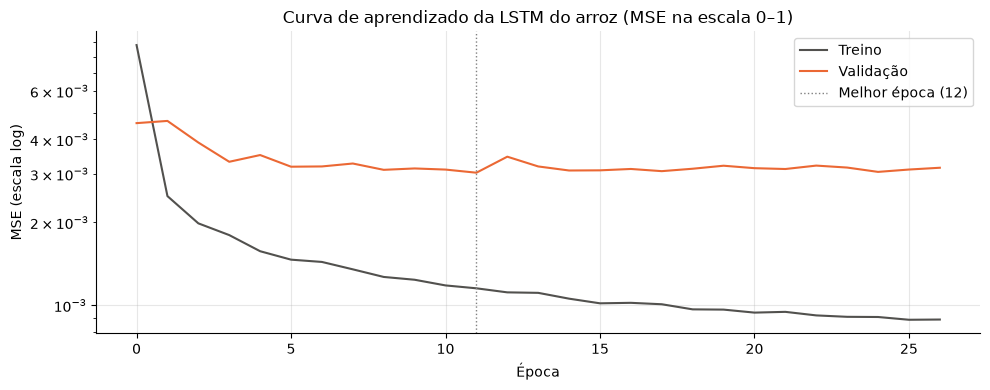

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(historico.history["loss"],     color="#52514e", lw=1.5, label="Treino")
ax.plot(historico.history["val_loss"], color="#eb6834", lw=1.5, label="Validação")
ax.axvline(melhor, color="gray", ls=":", lw=1, label=f"Melhor época ({melhor + 1})")
ax.set_yscale("log")
ax.set_title("Curva de aprendizado da LSTM do arroz (MSE na escala 0–1)")
ax.set_xlabel("Época")
ax.set_ylabel("MSE (escala log)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/lstm_curva_aprendizado_arroz.png", dpi=150)
plt.show()

## 5. Previsão recursiva de 30 passos no período de teste

### 5.1 Recursão com reconstrução do preço

Os 30 dias de teste são previstos **em horizonte fechado**, a partir de **31/01/2026**, sem ver nenhum preço do teste — o mesmo protocolo
do SARIMA/SARIMAX. A rede prevê variações; o preço é obtido acumulando-as sobre o último preço real ($P_T$, 31/01/2026):

$$\hat{P}_{T+h} = \hat{P}_{T+h-1} + \widehat{\Delta P}_{T+h} = P_T + \sum_{j=1}^{h} \widehat{\Delta P}_{T+j}, \qquad h = 1, \dots, 30$$

**Algoritmo** (para cada dia $d$ do teste, em ordem):

1. Montar a janela dos 30 dias anteriores a $d$ (37 variáveis), escalar com `escala_X` e prever a variação $\widehat{\Delta P}_d$ (após `inverse_transform`).
2. **Reconstruir** o preço: $\hat{P}_d = \hat{P}_{d-1} + \widehat{\Delta P}_d$ (no 1º dia, $\hat{P}_{d-1}$ é o preço real de 31/01/2026).
3. Gravar $\hat{P}_d$ no lugar do preço real de $d$ e recalcular, na linha de $d$, as **12 variáveis derivadas do preço** com as fórmulas do
   `build_features.py`: `preco_brl_lag_1/7/14/30`, `preco_brl_ma_7/14/30`, `preco_brl_std_7/14/30`, `preco_usd` ($\hat{P}_d$ / `dolar_venda`)
   e a própria variação `delta_preco_brl` ($\hat{P}_d - \hat{P}_{d-1}$). A janela do dia $d+1$ já carrega a previsão de $d$.

> **Exógenas:** câmbio, IPCA, Selic, clima e calendário do teste ficam com os valores **observados**, exatamente como no SARIMAX
> (que recebe as exógenas reais do teste em `exog`). Só a informação de **preço do arroz** é substituída pela previsão, que é justamente
> o que SARIMA/SARIMAX também não conhecem no teste.


In [9]:
PRECO_LAGS    = [1, 7, 14, 30]
PRECO_JANELAS = [7, 14, 30]
DERIVADAS = (["preco_usd", DELTA] + [f"preco_brl_lag_{k}" for k in PRECO_LAGS]
             + [f"preco_brl_{e}_{w}" for w in PRECO_JANELAS for e in ("ma", "std")])
assert set(DERIVADAS) <= set(FEATURES) and len(DERIVADAS) == 12

def atualizar_derivadas(df, data):
    # Recalcula, na linha `data`, as variáveis que dependem do preço (mesmas fórmulas do build_features.py)
    p   = df[ALVO]
    pos = df.index.get_loc(data)
    df.at[data, "preco_usd"] = p.iloc[pos] / df.at[data, "dolar_venda"]
    df.at[data, DELTA]       = p.iloc[pos] - p.iloc[pos - 1]
    for k in PRECO_LAGS:
        df.at[data, f"preco_brl_lag_{k}"] = p.iloc[pos - k]
    for w in PRECO_JANELAS:
        janela = p.iloc[pos - w + 1:pos + 1]
        df.at[data, f"preco_brl_ma_{w}"]  = janela.mean()
        df.at[data, f"preco_brl_std_{w}"] = janela.std()   # ddof=1, como o rolling().std() do pandas

# Sanidade: com os preços REAIS, a função reproduz o dataset (diferenças só de arredondamento a 4 casas;
# preco_usd tem tolerância maior porque o CEPEA usa o próprio dólar de referência, não o PTAX de venda)
copia = dados.loc[:teste.index[-1]].copy()
for d in teste.index:
    atualizar_derivadas(copia, d)
dif = (copia.loc[teste.index, DERIVADAS] - dados.loc[teste.index, DERIVADAS]).abs().max()
assert (dif.drop("preco_usd") < 1e-3).all() and dif["preco_usd"] / dados.loc[teste.index, "preco_usd"].mean() < 0.06
print("Maior diferença ao recalcular com preços reais:")
print(dif.round(4).to_string())

Maior diferença ao recalcular com preços reais:
preco_usd           0.0708
delta_preco_brl     0.0000
preco_brl_lag_1     0.0000
preco_brl_lag_7     0.0000
preco_brl_lag_14    0.0000
preco_brl_lag_30    0.0000
preco_brl_ma_7      0.0000
preco_brl_std_7     0.0000
preco_brl_ma_14     0.0000
preco_brl_std_14    0.0000
preco_brl_ma_30     0.0000
preco_brl_std_30    0.0000


In [10]:
def prever_recursivo(modelo, dados, datas_teste):
    # Prevê a variação de cada dia, reconstrói o preço (P_d = P_{d-1} + ΔP_d) e realimenta as janelas seguintes
    df = dados.loc[:datas_teste[-1]].copy()
    df.loc[datas_teste, ALVO] = np.nan            # nenhum preço do teste é conhecido
    precos, deltas = [], []
    for d in datas_teste:
        janela = df.loc[d - pd.Timedelta(days=LOOKBACK):d - pd.Timedelta(days=1), FEATURES]
        assert len(janela) == LOOKBACK and not janela.isna().any().any()
        x = escala_X.transform(janela)[np.newaxis]                      # (1, 30, 37)
        delta_hat = float(escala_y.inverse_transform(modelo.predict(x, verbose=0))[0, 0])
        preco_hat = df.at[d - pd.Timedelta(days=1), ALVO] + delta_hat  # reconstrução: P_d = P_{d-1} + ΔP_d
        deltas.append(delta_hat)
        precos.append(preco_hat)
        df.at[d, ALVO] = preco_hat                # o preço reconstruído passa a ser o "preço" de d ...
        atualizar_derivadas(df, d)                # ... e entra nas variáveis derivadas da linha d
    return (pd.Series(precos, index=datas_teste, name="previsto"),
            pd.Series(deltas, index=datas_teste, name="delta_previsto"))

y_teste = teste[ALVO]
y_prev, delta_prev = prever_recursivo(modelo, dados, y_teste.index)
assert (y_prev.index == y_teste.index).all()

# Sanidade: desfazer a escala do rótulo e somar ao preço real da véspera devolve exatamente o preço real
p_vespera = dados[ALVO].shift(1).loc[datas_te].values
assert np.allclose(escala_y.inverse_transform(y_te.reshape(-1, 1)).ravel() + p_vespera, y_teste.values, atol=1e-3)

# Previsão de 1 passo (preço real da véspera + variação prevista): mantida APENAS como referência para medir a propagação do erro
delta_1p  = escala_y.inverse_transform(modelo.predict(X_te, verbose=0)).ravel()
y_prev_1p = pd.Series(p_vespera + delta_1p, index=datas_te, name="previsto_1passo")
assert np.isclose(y_prev.iloc[0], y_prev_1p.iloc[0], atol=0.01)   # no 1º dia as duas janelas são idênticas (100% reais)

pd.DataFrame({"ΔP previsto (R$/saca)": delta_prev, "ΔP real (R$/saca)": dados.loc[y_teste.index, DELTA],
              "Preço reconstruído (R$/saca)": y_prev}).round(2).T


data,2026-02-01,2026-02-02,2026-02-03,2026-02-04,2026-02-05,2026-02-06,2026-02-07,2026-02-08,2026-02-09,2026-02-10,...,2026-02-21,2026-02-22,2026-02-23,2026-02-24,2026-02-25,2026-02-26,2026-02-27,2026-02-28,2026-03-01,2026-03-02
ΔP previsto (R$/saca),0.08,0.08,0.08,0.07,0.07,0.07,0.07,0.08,0.09,0.08,...,0.06,0.06,0.06,0.06,0.05,0.05,0.06,0.07,0.07,0.07
ΔP real (R$/saca),0.00,-0.01,0.26,0.03,0.01,0.05,0.00,0.00,0.09,0.14,...,0.00,0.00,0.00,0.19,0.09,-0.01,-0.02,0.00,0.00,-0.05
Preço reconstruído (R$/saca),54.09,54.17,54.24,54.31,54.38,54.45,54.52,54.60,54.69,54.77,...,55.50,55.56,55.62,55.67,55.72,55.77,55.83,55.90,55.97,56.04


### 5.2 Métricas

As métricas seguem as mesmas fórmulas dos notebooks anteriores, calculadas diretamente com NumPy sobre os **30 passos da projeção recursiva**
**reconstruídos** contra os 30 preços reais (a avaliação é sempre no preço em R\$/saca, não na variação):

| Métrica | Fórmula | O que mede |
|---|---|---|
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$ | erro em R\$/saca; pune mais os erros grandes |
| **MAE** | $\frac{1}{n}\sum \lvert y_t - \hat{y}_t \rvert$ | "em média, erramos X reais por saca por dia" |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y_t - \hat{y}_t}{y_t} \right\rvert$ | "em média, erramos X% do preço" |

Como referência, também calculamos a **previsão ingênua em horizonte fechado** (repetir o último preço do treino, 31/01/2026, nos 30 dias)
e a previsão de 1 passo da versão anterior deste notebook.

In [11]:
def metricas(y_real, y_hat):
    erro = np.asarray(y_real) - np.asarray(y_hat)
    return {"RMSE": np.sqrt(np.mean(erro ** 2)),
            "MAE":  np.mean(np.abs(erro)),
            "MAPE": np.mean(np.abs(erro / np.asarray(y_real))) * 100}

erro = y_teste.values - y_prev.values
m_rec = metricas(y_teste, y_prev)
rmse, mae, mape = m_rec["RMSE"], m_rec["MAE"], m_rec["MAPE"]

ingenuo = pd.Series(treino[ALVO].iloc[-1], index=y_teste.index)   # último preço conhecido, repetido 30 dias
referencias = pd.DataFrame({
    "LSTM em diferenças, recursiva (30 passos)": m_rec,
    "Ingênuo (último preço do treino)":    metricas(y_teste, ingenuo),
    "LSTM 1 passo (rolling, referência)":  metricas(y_teste, y_prev_1p),
}).T
# Resultado da versão anterior deste notebook (alvo em nível, mesma arquitetura e protocolo), para referência
referencias.loc["LSTM em nível, recursiva (versão anterior)"] = {"RMSE": 0.3431, "MAE": 0.3043, "MAPE": 0.5555}

print(f"LSTM em diferenças, recursiva (30 passos): RMSE = R$ {rmse:.2f} | MAE = R$ {mae:.2f} | MAPE = {mape:.2f}%\n")
referencias.round(2)

LSTM em diferenças, recursiva (30 passos): RMSE = R$ 0.34 | MAE = R$ 0.30 | MAPE = 0.54%



,RMSE,MAE,MAPE
"LSTM em diferenças, recursiva (30 passos)",0.34,0.30,0.54
Ingênuo (último preço do treino),0.95,0.80,1.46
"LSTM 1 passo (rolling, referência)",0.12,0.09,0.17
"LSTM em nível, recursiva (versão anterior)",0.34,0.30,0.56


Tabela dia a dia do período de teste:

In [12]:
comparacao = pd.DataFrame({
    "Passo (h)":               np.arange(1, len(y_teste) + 1),
    "ΔP real (R$/saca)":          dados.loc[y_teste.index, DELTA],
    "ΔP previsto (R$/saca)":      delta_prev,
    "Real (R$/saca)":             y_teste,
    "Previsto (R$/saca)":         y_prev,
    "Erro (R$/saca)":             y_teste - y_prev,
    "Previsto 1 passo (R$/saca)": y_prev_1p,
}).round(2)
comparacao.index = comparacao.index.strftime("%d/%m/%Y")
comparacao

,Passo (h),ΔP real (R$/saca),ΔP previsto (R$/saca),Real (R$/saca),Previsto (R$/saca),Erro (R$/saca),Previsto 1 passo (R$/saca)
data,,,,,,,
01/02/2026,1,0.00,0.08,54.01,54.09,-0.08,54.09
02/02/2026,2,-0.01,0.08,54.00,54.17,-0.17,54.09
03/02/2026,3,0.26,0.08,54.26,54.24,0.02,54.07
04/02/2026,4,0.03,0.07,54.29,54.31,-0.02,54.33
05/02/2026,5,0.01,0.07,54.30,54.38,-0.08,54.36
06/02/2026,6,0.05,0.07,54.35,54.45,-0.10,54.37
07/02/2026,7,0.00,0.07,54.35,54.52,-0.17,54.42
08/02/2026,8,0.00,0.08,54.35,54.60,-0.25,54.43
09/02/2026,9,0.09,0.09,54.44,54.69,-0.25,54.43


## 6. Propagação do erro na previsão recursiva

### 6.1 Discussão metodológica: propagação do erro

Na estratégia recursiva, a rede é **treinada** sempre com janelas de valores **reais** (*teacher forcing*), mas, no teste, é **usada** com janelas
que contêm suas próprias previsões. Isso gera três efeitos conhecidos na literatura de previsão multi-passo
(Taieb et al., 2012; Chevillon, 2007; Bengio et al., 2015 — *exposure bias*):

1. **Acúmulo do erro (*error propagation*):** o erro do passo $h$ entra na janela do passo $h+1$. Se $\hat{y}_{T+1}$ sai R\$ 10 abaixo do real,
   as defasagens, médias móveis e o `preco_usd` dos passos seguintes herdam esse desvio. Ao contrário do SARIMA, em que a variância
   da previsão cresce de forma **analítica** com $h$ (e aparece no intervalo de confiança), na LSTM a propagação é **não linear** e não tem
   expressão fechada: o erro pode ser amortecido, amplificado ou ficar "congelado", dependendo de como a rede responde a entradas fora do padrão.
2. **Distribuição diferente da do treino (*exposure bias*):** previsões de redes treinadas com MSE tendem a ser **mais suaves** do que a série
   real (a rede prevê a média condicional). Janelas com preços previstos têm, portanto, **volatilidade menor** do que qualquer janela vista no treino:
   as variáveis `preco_brl_std_7/14/30` encolhem a cada passo, e a rede passa a operar numa região do espaço de entrada que nunca viu.
3. **Achatamento ou deriva:** sem a "âncora" do preço real, a projeção recursiva tende a se estabilizar (achatar) ou a **derivar**
   numa direção, quando um pequeno viés do passo 1 é realimentado e reforçado a cada passo. Ela deixa de reagir a choques do teste porque nenhuma variável na janela
   carrega a informação de que o preço subiu. As únicas informações novas que entram são as exógenas (câmbio, clima, calendário).

**Por que aceitar esse custo?** Porque é a única forma de comparar a LSTM com o SARIMA/SARIMAX sob o **mesmo conjunto de informação**:
em 31/01/2026, nenhum dos modelos conhece o preço de fevereiro. A avaliação de 1 passo mede outra coisa (capacidade de corrigir a previsão
diariamente com o preço observado) e não é comparável. Alternativas que reduzem a propagação, fora do escopo deste trabalho, são a estratégia
**direta** (um modelo por horizonte), a **MIMO** (saída densa com os 30 dias de uma vez) e o treino com *scheduled sampling*.

O gráfico abaixo mede a propagação empiricamente: compara, passo a passo, o erro absoluto da projeção recursiva com o da previsão de 1 passo
(que usa o preço real até a véspera). A diferença entre as curvas é o erro **acumulado** pela recursão.

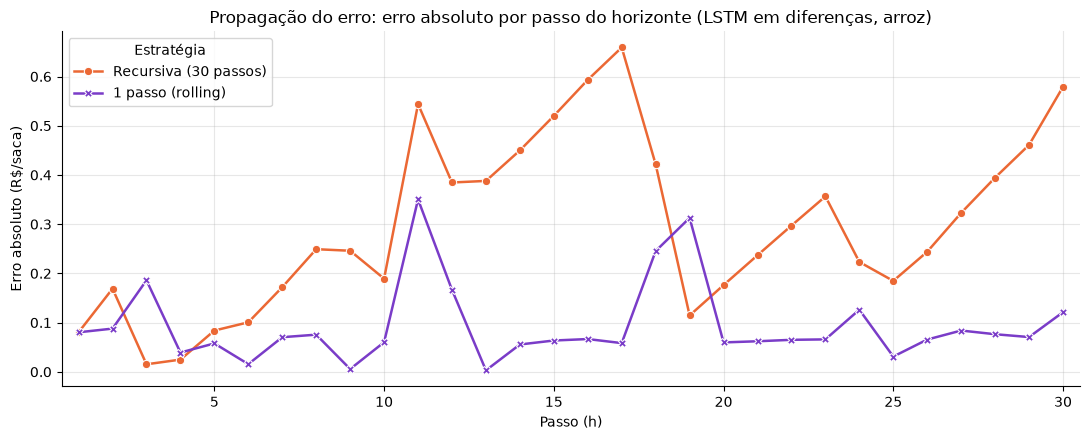

,MAE recursiva,MAE 1 passo,Amplitude da previsão recursiva,Amplitude do real
h = 1–10,0.13,0.07,0.68,0.58
h = 11–20,0.43,0.14,0.59,0.96
h = 21–30,0.33,0.08,0.54,0.28


In [13]:
prop = pd.DataFrame({
    "Passo (h)":             np.arange(1, len(y_teste) + 1),
    "Recursiva (30 passos)": np.abs(y_teste.values - y_prev.values),
    "1 passo (rolling)":     np.abs(y_teste.values - y_prev_1p.values),
}).melt(id_vars="Passo (h)", var_name="Estratégia", value_name="Erro absoluto (R$/saca)")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=prop, x="Passo (h)", y="Erro absoluto (R$/saca)", hue="Estratégia", style="Estratégia",
             palette={"Recursiva (30 passos)": "#eb6834", "1 passo (rolling)": "#7a3cc8"},
             markers=True, dashes=False, lw=1.8, ax=ax)
ax.set_title("Propagação do erro: erro absoluto por passo do horizonte (LSTM em diferenças, arroz)")
ax.set_xlim(0.5, len(y_teste) + 0.5)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/lstm_propagacao_erro_arroz.png", dpi=150)
plt.show()

# Resumo por blocos do horizonte
blocos = pd.cut(np.arange(1, len(y_teste) + 1), bins=[0, 10, 20, 30], labels=["h = 1–10", "h = 11–20", "h = 21–30"])
pd.DataFrame({
    "MAE recursiva":        pd.Series(np.abs(y_teste.values - y_prev.values)).groupby(blocos).mean(),
    "MAE 1 passo":          pd.Series(np.abs(y_teste.values - y_prev_1p.values)).groupby(blocos).mean(),
    "Amplitude da previsão recursiva": pd.Series(y_prev.values).groupby(blocos).agg(lambda s: s.max() - s.min()),
    "Amplitude do real":    pd.Series(y_teste.values).groupby(blocos).agg(lambda s: s.max() - s.min()),
}).round(2)

### 6.2 Efeito da modelagem em diferenças

**No arroz, a versão em nível não colapsou**, ao contrário do trigo. Ela errava pouco no 1º passo (0,24 R\$/saca) e a deriva que se propagava
na recursão era de alta, na mesma direção do mercado. Por isso a diferenciação aqui **não muda o resultado**: o RMSE em 30 dias passa de
0,3431 para 0,3435 R\$/saca.

O que muda é **como** o erro se forma:

1. **Ancoragem no último preço real.** O erro do passo 1 cai de 0,24 para 0,08 R\$/saca, porque a projeção parte de $P_T$ (54,01 R\$/saca).
   Na previsão de 1 passo (preço real da véspera + $\widehat{\Delta P}$), o RMSE cai de 0,22 para 0,12 R\$/saca.
2. **Erro que cresce de forma controlada.** O preço reconstruído é uma rampa praticamente reta: as variações previstas ficam entre
   +0,05 e +0,09 R\$/saca por dia. Com inclinação prevista de +0,07 contra +0,05 realizada, o erro cresce de forma aproximadamente
   linear até o platô de preço de 11 a 17/02 (erro máximo de 0,66 R\$/saca em 17/02) e depois se estabiliza:

| MAE por bloco do horizonte (R\$/saca) | h = 1–10 | h = 11–20 | h = 21–30 |
|---|---|---|---|
| LSTM em nível, recursiva (versão anterior) | 0,21 | 0,43 | 0,28 |
| **LSTM em diferenças, recursiva** | **0,13** | **0,43** | **0,33** |
| LSTM em diferenças, 1 passo (referência) | 0,07 | 0,14 | 0,08 |

**O que a diferenciação não resolveu: a rede não aprendeu a variação diária do arroz.** No diagnóstico abaixo, na validação (655 dias),
a LSTM tem MSE **3,6% pior** do que prever sempre a variação média do treino (+0,01 R\$/saca), com correlação de 0,035 entre
$\widehat{\Delta P}$ e $\Delta P$ e acerto de sinal de 48% (abaixo do acaso). No teste, as variações previstas são praticamente constantes
(desvio-padrão de 0,008 contra 0,12 R\$/saca das reais). O acerto de sinal de 71% no teste não indica habilidade: a rede prevê alta todos
os dias, e o preço subiu na maioria dos dias com mudança.

Na prática, a LSTM em diferenças funciona aqui como um **ingênuo com tendência**, cuja inclinação (+0,07 R\$/saca por dia) foi aprendida
pela rede. Ela supera o ingênuo com a tendência dos últimos 30 dias do treino (+0,02 por dia, RMSE = 0,63) porque a inclinação projetada ficou
mais próxima da alta realizada no teste. Mas, como no trigo, um único período de 30 dias não permite separar habilidade de coincidência.


In [14]:
# Diagnóstico 1 — a rede acerta a variação de cada dia? (1 passo, janelas reais da validação do Keras = últimos 10% do treino)
corte  = int(len(X_tr) * (1 - 0.1))
dv_real = escala_y.inverse_transform(y_tr[corte:].reshape(-1, 1)).ravel()
dv_prev = escala_y.inverse_transform(modelo.predict(X_tr[corte:], verbose=0)).ravel()
media_treino = treino[DELTA].iloc[:LOOKBACK + corte].mean()        # "prever sempre a variação média" (sem olhar a validação)
mse = lambda e: np.mean(np.asarray(e) ** 2)
mov = dv_real != 0                                                 # dias em que o preço mudou

d_teste_real = dados.loc[y_teste.index, DELTA].values
diag_delta = pd.DataFrame({
    "Correlação ΔP previsto × real": [np.corrcoef(dv_prev, dv_real)[0, 1], np.corrcoef(delta_1p, d_teste_real)[0, 1]],
    "Acerto do sinal (dias com mudança)": [np.mean(np.sign(dv_prev[mov]) == np.sign(dv_real[mov])),
                                           np.mean(np.sign(delta_1p[d_teste_real != 0]) == np.sign(d_teste_real[d_teste_real != 0]))],
    "Desvio-padrão ΔP previsto (R$/saca)": [dv_prev.std(), delta_1p.std()],
    "Desvio-padrão ΔP real (R$/saca)":     [dv_real.std(), d_teste_real.std()],
}, index=[f"Validação ({len(dv_real)} dias)", "Teste, 1 passo (30 dias)"])
print(f"Validação: MSE da LSTM = {mse(dv_real - dv_prev):.2f}  |  MSE prevendo sempre a média do treino ({media_treino:+.2f} R$/saca) = "
      f"{mse(dv_real - media_treino):.2f}  ->  ganho de {(1 - mse(dv_real - dv_prev) / mse(dv_real - media_treino)):.1%}")
display(diag_delta.round(3))

# Diagnóstico 2 — a LSTM faz mais do que extrapolar a tendência recente? Ingênuo com tendência (drift) em horizonte fechado:
# P_T + h × (variação média dos últimos k dias do treino)
h = np.arange(1, len(y_teste) + 1)
P_T = treino[ALVO].iloc[-1]
deriva = {}
for k in [30, 90]:
    inclinacao = (P_T - treino[ALVO].iloc[-1 - k]) / k
    deriva[f"Ingênuo com tendência ({k} dias: {inclinacao:+.2f} R$/saca por dia)"] = metricas(y_teste, P_T + inclinacao * h)
inclinacao_lstm = (y_prev.iloc[-1] - P_T) / len(y_teste)
inclinacao_real = (y_teste.iloc[-1] - P_T) / len(y_teste)
print(f"\nInclinação média: LSTM = {inclinacao_lstm:+.2f} R$/saca por dia | real no teste = {inclinacao_real:+.2f} R$/saca por dia")
pd.concat([referencias.loc[["LSTM em diferenças, recursiva (30 passos)", "Ingênuo (último preço do treino)"]],
           pd.DataFrame(deriva).T]).round(2)


Validação: MSE da LSTM = 0.27  |  MSE prevendo sempre a média do treino (+0.01 R$/saca) = 0.27  ->  ganho de -3.6%


,Correlação ΔP previsto × real,Acerto do sinal (dias com mudança),Desvio-padrão ΔP previsto (R$/saca),Desvio-padrão ΔP real (R$/saca)
Validação (655 dias),0.035,0.478,0.080,0.508
"Teste, 1 passo (30 dias)",-0.248,0.706,0.008,0.120



Inclinação média: LSTM = +0.07 R$/saca por dia | real no teste = +0.05 R$/saca por dia


,RMSE,MAE,MAPE
"LSTM em diferenças, recursiva (30 passos)",0.34,0.30,0.54
Ingênuo (último preço do treino),0.95,0.80,1.46
Ingênuo com tendência (30 dias: +0.02 R$/saca por dia),0.63,0.52,0.94
Ingênuo com tendência (90 dias: -0.03 R$/saca por dia),1.40,1.20,2.18


## 7. Visualização gráfica e exportação

### 7.1 Gráfico: Real vs. Previsão LSTM em diferenças (recursiva)

Mesmo padrão dos gráficos do SARIMA/SARIMAX do arroz: últimos 90 dias do treino, seguidos dos 30 dias de teste, com a
mesma escala vertical (52 a 57 R\$/saca) para comparação visual justa. A previsão recursiva é a principal (tracejada laranja);
a de 1 passo aparece em linha fina apenas como referência. A LSTM não fornece intervalo de confiança nativamente.

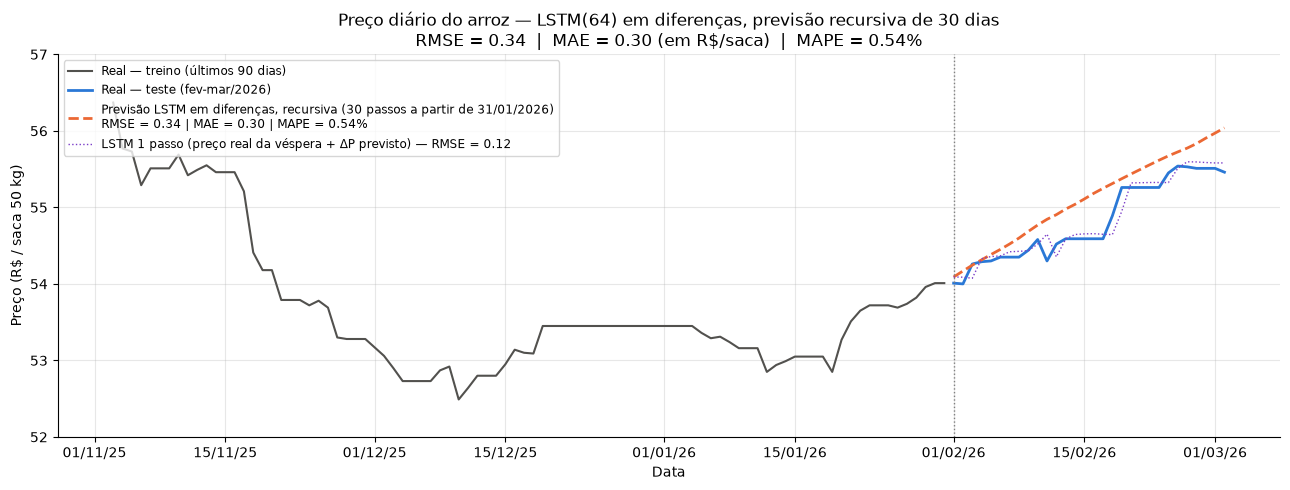

In [15]:
contexto = treino[ALVO].iloc[-90:]   # últimos 90 dias do treino

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(contexto,  color="#52514e", lw=1.5, label="Real — treino (últimos 90 dias)")
ax.plot(y_teste,   color="#2a78d6", lw=2,   label="Real — teste (fev-mar/2026)")
ax.plot(y_prev,    color="#eb6834", lw=2, ls="--",
        label=f"Previsão LSTM em diferenças, recursiva (30 passos a partir de 31/01/2026)\n"
              f"RMSE = {rmse:.2f} | MAE = {mae:.2f} | MAPE = {mape:.2f}%")
ax.plot(y_prev_1p, color="#7a3cc8", lw=1, ls=":",
        label=f"LSTM 1 passo (preço real da véspera + ΔP previsto) — RMSE = {referencias.loc['LSTM 1 passo (rolling, referência)', 'RMSE']:.2f}")
ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço diário do arroz — LSTM(64) em diferenças, previsão recursiva de 30 dias\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$/saca)  |  MAPE = {mape:.2f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(52, 57)   # mesma escala nos gráficos de SARIMA, SARIMAX e LSTM do arroz
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/lstm_previsao_arroz.png", dpi=150)
plt.show()

### 7.2 Diagnóstico dos erros (Seaborn)

Dois complementos ao gráfico principal, ambos sobre a **previsão recursiva**:

- **Dispersão real × previsto:** pontos sobre a diagonal tracejada ($\hat{y} = y$) indicam acerto; pontos sistematicamente abaixo
  da diagonal indicam que o modelo **subestima** o preço (e acima, que superestima). Uma faixa horizontal de pontos indica uma projeção
  **achatada**, que não acompanha a variação do real.
- **Erro dia a dia:** barras positivas = preço real acima do previsto. Uma sequência longa de barras do mesmo sinal indica **viés**.

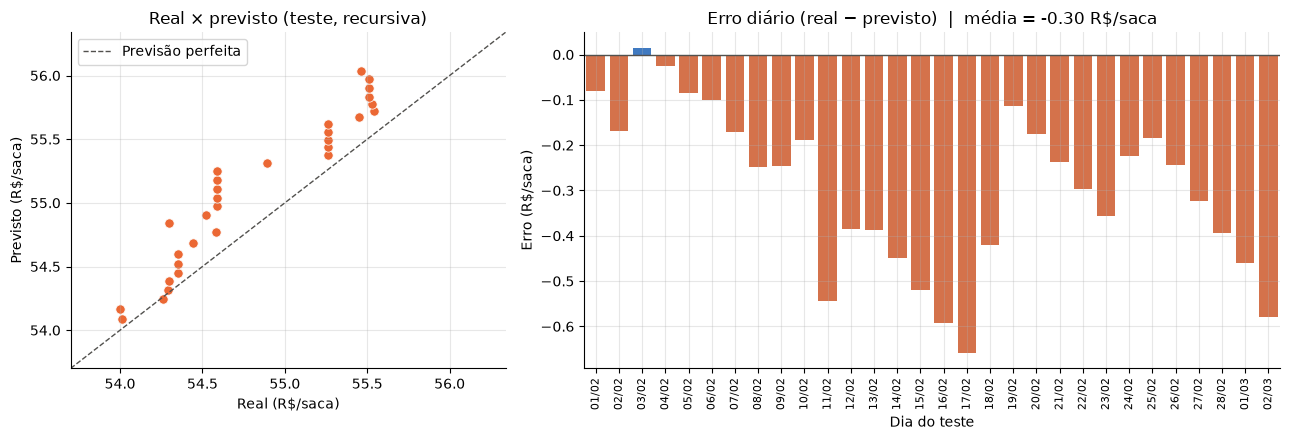

In [16]:
diag = pd.DataFrame({"real": y_teste.values, "previsto": y_prev.values, "erro": erro}, index=y_teste.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})

# Dispersão real x previsto
sns.scatterplot(data=diag, x="real", y="previsto", color="#eb6834", s=45, edgecolor="white", ax=ax1)
lim = [min(diag["real"].min(), diag["previsto"].min()) - 0.3, max(diag["real"].max(), diag["previsto"].max()) + 0.3]
ax1.plot(lim, lim, color="#52514e", ls="--", lw=1, label="Previsão perfeita")
ax1.set_xlim(lim); ax1.set_ylim(lim)
ax1.set_title("Real × previsto (teste, recursiva)")
ax1.set_xlabel("Real (R$/saca)")
ax1.set_ylabel("Previsto (R$/saca)")
ax1.legend(loc="upper left")

# Erro por dia
cores = np.where(diag["erro"] >= 0, "#2a78d6", "#eb6834")
sns.barplot(x=diag.index.strftime("%d/%m"), y=diag["erro"], palette=list(cores), ax=ax2)
ax2.axhline(0, color="#52514e", lw=1)
ax2.set_title(f"Erro diário (real − previsto)  |  média = {diag['erro'].mean():+.2f} R$/saca")
ax2.set_xlabel("Dia do teste")
ax2.set_ylabel("Erro (R$/saca)")
ax2.tick_params(axis="x", rotation=90, labelsize=8)

for a in (ax1, ax2):
    a.grid(alpha=0.3)
    a.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/lstm_diagnostico_arroz.png", dpi=150)
plt.show()

### 7.3 Exportação das previsões e métricas

- `metricas_lstm_arroz.csv` — mesmo formato do `metricas_sarima_arroz.csv` e do `metricas_sarimax_arroz.csv` (`modelo, RMSE, MAE, MAPE`), agora com as métricas da
  **previsão recursiva de 30 passos**;
- `previsoes_lstm_arroz.csv` — série diária do teste (`data, real, previsto, erro`) da previsão recursiva, mais as colunas
  `delta_previsto` (variação prevista) e `previsto_1passo` (referência), para a análise comparativa com o SARIMAX.

In [17]:
NOME_MODELO = "LSTM(64) em diferenças, recursiva (30 passos)"

pd.DataFrame({"modelo": [NOME_MODELO], "RMSE": [rmse], "MAE": [mae], "MAPE": [mape]}) \
  .round(4).to_csv(f"{PASTA_SAIDA}/metricas_lstm_arroz.csv", index=False)

diag.assign(delta_previsto=delta_prev.values, previsto_1passo=y_prev_1p.values).rename_axis("data").round(4) \
    .to_csv(f"{PASTA_SAIDA}/previsoes_lstm_arroz.csv", date_format="%Y-%m-%d")

for arquivo in ["lstm_previsao_arroz.png", "lstm_diagnostico_arroz.png", "lstm_propagacao_erro_arroz.png",
                "lstm_curva_aprendizado_arroz.png", "metricas_lstm_arroz.csv", "previsoes_lstm_arroz.csv"]:
    caminho = os.path.join(PASTA_SAIDA, arquivo)
    print(f"{caminho:<42} salvo: {os.path.exists(caminho)}  ({os.path.getsize(caminho):,} bytes)")

pd.read_csv(f"{PASTA_SAIDA}/metricas_lstm_arroz.csv")

outputs\lstm_previsao_arroz.png            salvo: True  (123,023 bytes)
outputs\lstm_diagnostico_arroz.png         salvo: True  (101,499 bytes)
outputs\lstm_propagacao_erro_arroz.png     salvo: True  (112,640 bytes)
outputs\lstm_curva_aprendizado_arroz.png   salvo: True  (63,519 bytes)
outputs\metricas_lstm_arroz.csv            salvo: True  (92 bytes)
outputs\previsoes_lstm_arroz.csv           salvo: True  (1,499 bytes)


,modelo,RMSE,MAE,MAPE
0,"LSTM(64) em diferenças, recursiva (30 passos)",0.3435,0.296,0.5395


### 7.4 Comparação com os modelos estatísticos do arroz (horizonte fechado de 30 dias)

Agora os três modelos são avaliados sob o **mesmo protocolo**: previsão dos 30 dias de teste a partir de 31/01/2026, sem nenhum
preço do teste, com as exógenas observadas (no SARIMAX e na LSTM). A previsão ingênua (último preço do treino repetido) entra como piso de referência.

In [18]:
sarima  = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarima_arroz.csv").set_index("modelo")
sarimax = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarimax_arroz.csv").set_index("modelo")
lstm    = pd.read_csv(f"{PASTA_SAIDA}/metricas_lstm_arroz.csv").set_index("modelo")
ingen   = referencias.loc[["Ingênuo (último preço do treino)", "LSTM em nível, recursiva (versão anterior)"]]

tabela = pd.concat([sarima, sarimax, lstm, ingen])[["RMSE", "MAE", "MAPE"]]
tabela["Δ RMSE vs. SARIMA (%)"] = (tabela["RMSE"] / sarima["RMSE"].iloc[0] - 1) * 100
tabela.index.name = "modelo (30 dias, horizonte fechado)"
tabela.round(2)

,RMSE,MAE,MAPE,Δ RMSE vs. SARIMA (%)
"modelo (30 dias, horizonte fechado)",,,,
SARIMA,0.47,0.35,0.64,0.00
SARIMAX,0.47,0.35,0.64,-0.06
"LSTM(64) em diferenças, recursiva (30 passos)",0.34,0.30,0.54,-26.26
Ingênuo (último preço do treino),0.95,0.80,1.46,104.69
"LSTM em nível, recursiva (versão anterior)",0.34,0.30,0.56,-26.34


## Conclusão

**Protocolo único (horizonte fechado de 30 dias a partir de 31/01/2026):**

| Modelo | RMSE | MAE | MAPE | Δ RMSE vs. SARIMA |
|---|---|---|---|---|
| SARIMA | 0,47 | 0,35 | 0,64% | — |
| SARIMAX | 0,47 | 0,35 | 0,64% | −0,1% |
| **LSTM(64) em diferenças, recursiva** | **0,34** | **0,30** | **0,54%** | **−26,3%** |
| Ingênuo (último preço do treino) | 0,95 | 0,80 | 1,46% | +104,7% |
| Ingênuo com tendência (últimos 30 dias) | 0,63 | 0,52 | 0,94% | +35,0% |
| LSTM em nível, recursiva (versão anterior) | 0,34 | 0,30 | 0,56% | −26,3% |

- **A diferenciação não alterou o desempenho do arroz em 30 dias** (RMSE de 0,3431 em nível contra 0,3435 em diferenças). A melhora aparece só
  no curtíssimo prazo: erro do 1º passo de 0,24 para 0,08 R\$/saca e RMSE de 1 passo de 0,22 para 0,12 R\$/saca.
- **A LSTM continua com o menor erro entre os modelos do arroz** (RMSE 26% menor que o do SARIMA/SARIMAX). Com o alvo em diferenças, porém, fica
  explícito que o resultado vem de uma **tendência linear aprendida** (+0,07 R\$/saca por dia), e não da previsão dos movimentos diários: na validação,
  a rede é 3,6% pior do que prever a variação média.
- **Leitura conjunta com o trigo:** a diferenciação foi decisiva no trigo, onde a versão em nível colapsou (RMSE de 59,28 para 6,90 R\$/t), e neutra
  no arroz, onde a versão em nível já seguia a direção do mercado. Nas duas culturas, a vantagem da LSTM sobre o SARIMA/SARIMAX em 30 dias vem
  da inclinação projetada e não da previsão diária. Isso reforça a necessidade de uma avaliação com várias origens de previsão (*rolling origin*)
  antes de afirmar a superioridade de qualquer modelo.
